# Corporate Transaction Anomaly Detection: walkthrough

Labelled fraud is scarce in corporate banking, so detection starts **unsupervised**. Three detectors look at the problem from different angles:

| Detector | Catches |
|---|---|
| **Isolation Forest** | Globally unusual combinations of features |
| **DBSCAN** | Transactions that sit in no dense "normal" neighbourhood |
| **Statistical rules** | Amount far from the client's own norm, odd hours, bursts, amounts just under reporting thresholds |

*Synthetic data with injected, labelled anomalies, so the fix can be measured.*

In [1]:
import warnings; warnings.filterwarnings("ignore")
import subprocess, sys, json, pandas as pd
from IPython.display import Image, display
subprocess.run([sys.executable, "data/generate_synthetic.py"], check=True, capture_output=True)
from src.features import build_features, FEATURES
d = build_features()
d.groupby("anomaly_type")[FEATURES[:-1]].mean().round(2)

,amount_robust_z,hour_z,is_weekend,new_counterparty,txns_prev_60min,near_threshold
anomaly_type,,,,,,
BURST,0.44,0.69,0.22,0.94,4.41,0.01
LARGE_AMOUNT,5.08,0.95,0.39,0.07,0.25,0.05
NEW_CPTY_LARGE,3.51,0.91,0.27,0.93,0.30,0.00
NORMAL,-0.01,0.80,0.08,0.02,0.69,0.01
ODD_HOUR,1.76,4.24,0.24,0.10,0.00,0.02
STRUCTURING,3.15,0.95,0.32,0.94,0.25,1.00


## 1. Features are relative to each client
A ₦50m payment is routine for one client and alarming for another. Amount is a **robust z-score within client** (median and IQR), hour is compared with the client's usual hours, and velocity is counted per client in a 60-minute window (`sql/01_txn_features.sql`).

## 2. Tuning instead of guessing

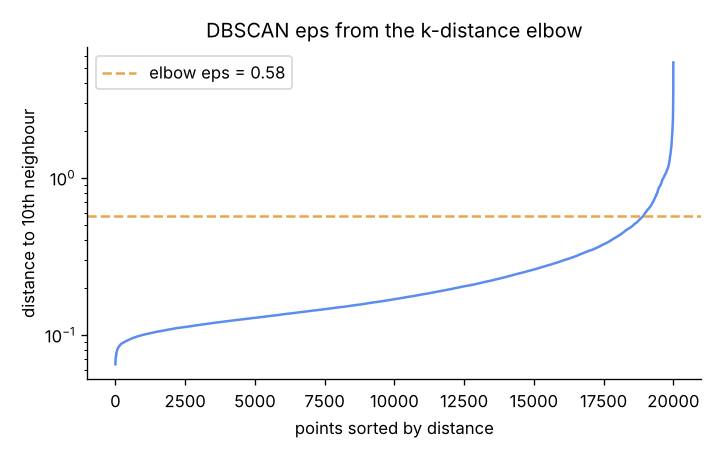

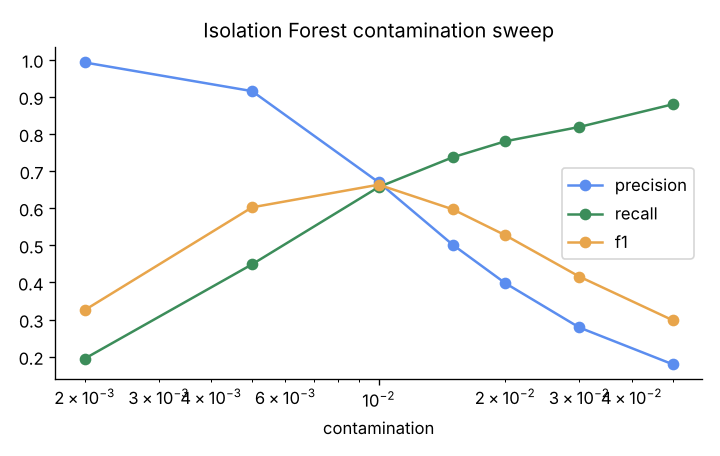

In [2]:
subprocess.run([sys.executable, "run_pipeline.py"], check=True, capture_output=True)
display(Image("reports/figures/k_distance_elbow.png", width=520))
display(Image("reports/figures/contamination_sweep.png", width=520))

* **DBSCAN eps:** taken from the knee of the sorted k-distance curve, not hard-coded.
* **Isolation Forest contamination:** swept and scored against a labelled sample. Precision falls fast past ~1%.

## 3. The fix: agreement voting instead of OR

,alerts,precision,recall,f1,auc
isolation_forest,660.0,0.6697,0.6568,0.6632,NaN
dbscan,2010.0,0.2821,0.8425,0.4227,NaN
statistical,4867.0,0.1118,0.8083,0.1964,NaN
ensemble_OR (original),5825.0,0.1071,0.9272,0.1921,0.9543
ensemble_2of3 (fix),1206.0,0.4668,0.8366,0.5993,0.9543
ensemble_3of3,506.0,0.7233,0.5438,0.6209,0.9543


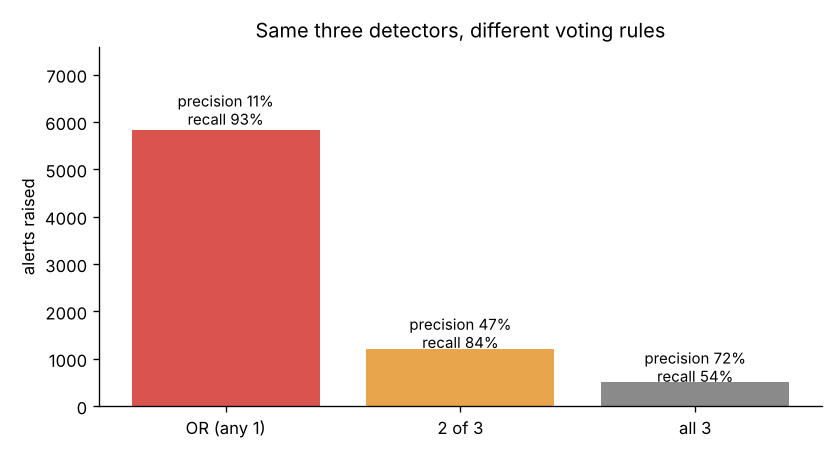

In [3]:
display(pd.read_csv("reports/detector_comparison.csv", index_col=0))
display(Image("reports/figures/ensemble_alerts.png", width=620))

The original **OR** rule fires if *any* detector does, so every detector's false positives add up. Requiring **2 of 3** cuts alerts by about 79% and raises precision about 4×, while still catching over 80% of anomalies.

In [4]:
pd.read_csv('reports/recall_by_type.csv')

,anomaly_type,n,recall_2of3
0,BURST,350,0.720
1,LARGE_AMOUNT,44,0.977
2,NEW_CPTY_LARGE,44,0.773
3,ODD_HOUR,50,0.980
4,STRUCTURING,185,1.000


Bursts are the hardest type: each payment on its own looks normal. A natural next step is sequence-level features, which the supervised LSTM/Conv1D direction was exploring.